In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import shap
import matplotlib.pyplot as plt

/Users/shanjayakasht/project/MLDA PROJECT/Patient-Independent-ECG-Arrhythmia-Classification/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
X = np.load("X.npy")
y = np.load("y.npy")
patient_ids = np.load("patient_ids.npy")

print("X:", X.shape)
print("y:", y.shape)
print("patient_ids:", patient_ids.shape)

print("Classes:", np.unique(y, return_counts=True))

X: (99536, 250)
y: (99536,)
patient_ids: (99536,)
Classes: (array([0, 1, 2, 3]), array([74761, 15327,  2546,  6902]))


In [3]:
# Fixed patient-wise DS1 / DS2 split

DS1 = [
    101,106,108,109,112,114,115,116,118,119,122,124,
    201,203,205,207,208,209,215,220,223,230
]

DS2 = [
    100,103,105,111,113,117,121,123,
    200,202,210,212,213,214,219,221,
    222,228,231,232,233,234
]

train_mask = np.isin(patient_ids, DS1)
test_mask  = np.isin(patient_ids, DS2)

X_train2 = X[train_mask]
X_test2  = X[test_mask]

y_train2 = y[train_mask]
y_test2  = y[test_mask]

train_patients = set(patient_ids[train_mask])
test_patients  = set(patient_ids[test_mask])

overlap = train_patients.intersection(test_patients)

print("Training beats :", X_train2.shape)
print("Testing beats  :", X_test2.shape)
print("Training labels:", y_train2.shape)
print("Testing labels :", y_test2.shape)

print("\nTrain patients:", len(train_patients))
print("Test patients :", len(test_patients))
print("Patient overlap:", overlap)

assert len(overlap) == 0, "DATA LEAKAGE DETECTED!"
print("\n✅ Patient-wise split verified: ZERO overlap")

Training beats : (50341, 250)
Testing beats  : (49195, 250)
Training labels: (50341,)
Testing labels : (49195,)

Train patients: 22
Test patients : 22
Patient overlap: set()

✅ Patient-wise split verified: ZERO overlap


In [4]:
# Add channel dimension for Conv1D

X_train2_cnn = X_train2[..., np.newaxis]
X_test2_cnn  = X_test2[..., np.newaxis]

print("CNN train shape:", X_train2_cnn.shape)
print("CNN test shape :", X_test2_cnn.shape)

CNN train shape: (50341, 250, 1)
CNN test shape : (49195, 250, 1)


In [5]:
from tensorflow.keras.utils import to_categorical

num_classes = len(np.unique(y))

# CNN input shape
X_reshaped = X.reshape(-1, X.shape[1], 1)

# One-hot labels
y_cat = to_categorical(y, num_classes=num_classes)

DS1 = [
    101,106,108,109,112,114,115,116,118,119,122,124,
    201,203,205,207,208,209,215,220,223,230
]

DS2 = [
    100,103,105,111,113,117,121,123,
    200,202,210,212,213,214,219,221,
    222,228,231,232,233,234
]

train_mask = np.isin(patient_ids, DS1)
test_mask = np.isin(patient_ids, DS2)

X_train2 = X_reshaped[train_mask]
X_test2  = X_reshaped[test_mask]

y_train2 = y_cat[train_mask]
y_test2  = y_cat[test_mask]

print("X_train2:", X_train2.shape)
print("X_test2 :", X_test2.shape)
print("y_train2:", y_train2.shape)
print("y_test2 :", y_test2.shape)

overlap = set(patient_ids[train_mask]) & set(patient_ids[test_mask])

print("Patient overlap:", overlap)

assert len(overlap) == 0
print("✅ Zero patient overlap")

X_train2: (50341, 250, 1)
X_test2 : (49195, 250, 1)
y_train2: (50341, 4)
y_test2 : (49195, 4)
Patient overlap: set()
✅ Zero patient overlap


In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout

def build_cnn(input_len, num_classes):
    model = Sequential([
        Conv1D(
            32,
            5,
            activation='relu',
            input_shape=(input_len, 1)
        ),

        MaxPooling1D(2),

        Conv1D(
            64,
            5,
            activation='relu'
        ),

        MaxPooling1D(2),

        Flatten(),

        Dense(
            64,
            activation='relu'
        ),

        Dropout(0.3),

        Dense(
            num_classes,
            activation='softmax'
        )
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [7]:
from sklearn.utils.class_weight import compute_class_weight

# Integer labels needed for class-weight calculation
y_train2_int = y[train_mask]

weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train2_int),
    y=y_train2_int
)

class_weight = dict(
    zip(np.unique(y_train2_int), weights)
)

print("Class weights:", class_weight)

model2 = build_cnn(
    X.shape[1],
    num_classes
)

history2 = model2.fit(
    X_train2,
    y_train2,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    class_weight=class_weight
)

Class weights: {np.int64(0): np.float64(0.33014821615949635), np.int64(1): np.float64(1.628526138716356), np.int64(2): np.float64(15.537345679012345), np.int64(3): np.float64(3.417119196307358)}
Epoch 1/10


/Users/shanjayakasht/project/MLDA PROJECT/Patient-Independent-ECG-Arrhythmia-Classification/.venv/lib/python3.9/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


708/708 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8206 - loss: 0.4975 - val_accuracy: 0.9549 - val_loss: 0.1978
Epoch 2/10
708/708 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9394 - loss: 0.1808 - val_accuracy: 0.9432 - val_loss: 0.3608
Epoch 3/10
708/708 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9513 - loss: 0.1367 - val_accuracy: 0.7184 - val_loss: 0.4870
Epoch 4/10
708/708 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9580 - loss: 0.1152 - val_accuracy: 0.9106 - val_loss: 0.2852
Epoch 5/10
708/708 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9622 - loss: 0.1039 - val_accuracy: 0.8685 - val_loss: 0.3183
Epoch 6/10
708/708 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9704 - loss: 0.0842 - val_accuracy: 0.8403 - val_loss: 0.3724
Epoch 7/10
708/708 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9706 - loss: 0.0730 - val_accuracy: 0.7470 - val_loss: 0.6134
Epoch 8/10
708/708 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9721 - loss: 0.0730 - val_accuracy: 0.8572 - val_

In [8]:
model2.save("model2_corrected.keras")
print("✅ model2 saved")

✅ model2 saved


In [9]:
y_prob2 = model2.predict(X_test2)

y_pred2 = y_prob2.argmax(axis=1)
y_true2 = y_test2.argmax(axis=1)

print("y_true2:", y_true2.shape)
print("y_pred2:", y_pred2.shape)

1538/1538 ━━━━━━━━━━━━━━━━━━━━ 1s 709us/step
y_true2: (49195,)
y_pred2: (49195,)


In [10]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

acc2 = accuracy_score(
    y_true2,
    y_pred2
)

macro_f1_2 = f1_score(
    y_true2,
    y_pred2,
    average="macro"
)

print("Corrected Accuracy:", acc2)
print("Corrected Macro-F1:", macro_f1_2)

print("\nClassification Report:")
print(
    classification_report(
        y_true2,
        y_pred2,
        target_names=[
            "Normal",
            "BBB",
            "APB",
            "PVC"
        ],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_true2,
        y_pred2
    )
)

Corrected Accuracy: 0.6943185283057222
Corrected Macro-F1: 0.3694226723567577

Classification Report:
              precision    recall  f1-score   support

      Normal       0.87      0.84      0.86     36641
         BBB       0.18      0.01      0.02      7599
         APB       0.05      0.14      0.07      1736
         PVC       0.37      0.93      0.53      3219

    accuracy                           0.69     49195
   macro avg       0.37      0.48      0.37     49195
weighted avg       0.70      0.69      0.68     49195


Confusion Matrix:
[[30828   418  4175  1220]
 [ 3039   102   754  3704]
 [ 1277     0   240   219]
 [  154    55    23  2987]]


In [11]:
import shap
import numpy as np
import matplotlib.pyplot as plt
import os

CLASS_NAMES = {
    0: "Normal",
    1: "BBB",
    2: "APB",
    3: "PVC"
}

# Find misclassified BBB beats
bbb_wrong = np.where(
    (y_true2 == 1) & (y_pred2 != 1)
)[0]

# Find misclassified APB beats
apb_wrong = np.where(
    (y_true2 == 2) & (y_pred2 != 2)
)[0]

print("Misclassified BBB:", len(bbb_wrong))
print("Misclassified APB:", len(apb_wrong))

Misclassified BBB: 7497
Misclassified APB: 1496


In [12]:
rng = np.random.default_rng(42)

bbb_selected = rng.choice(
    bbb_wrong,
    size=min(5, len(bbb_wrong)),
    replace=False
)

apb_selected = rng.choice(
    apb_wrong,
    size=min(5, len(apb_wrong)),
    replace=False
)

selected_indices = np.concatenate([
    bbb_selected,
    apb_selected
])

print("BBB selected:", bbb_selected)
print("APB selected:", apb_selected)

print("\nSelected samples:")
for idx in selected_indices:
    print(
        idx,
        "| True:",
        CLASS_NAMES[y_true2[idx]],
        "| Predicted:",
        CLASS_NAMES[y_pred2[idx]]
    )

BBB selected: [30811 24688 29803  7590 24572]
APB selected: [43386 41651 42507 42971 42917]

Selected samples:
30811 | True: BBB | Predicted: PVC
24688 | True: BBB | Predicted: APB
29803 | True: BBB | Predicted: PVC
7590 | True: BBB | Predicted: Normal
24572 | True: BBB | Predicted: PVC
43386 | True: APB | Predicted: Normal
41651 | True: APB | Predicted: Normal
42507 | True: APB | Predicted: PVC
42971 | True: APB | Predicted: Normal
42917 | True: APB | Predicted: Normal


In [13]:
background_indices = rng.choice(
    len(X_train2),
    size=200,
    replace=False
)

background = X_train2[background_indices]

X_explain = X_test2[selected_indices]

print("Background:", background.shape)
print("Explain data:", X_explain.shape)

Background: (200, 250, 1)
Explain data: (10, 250, 1)


In [14]:
explainer = shap.GradientExplainer(
    model2,
    background
)

shap_values = explainer.shap_values(
    X_explain
)

print("SHAP computed successfully")
print("SHAP type:", type(shap_values))

if isinstance(shap_values, list):
    print("Number of classes:", len(shap_values))
    print("Shape:", shap_values[0].shape)
else:
    print("Shape:", np.asarray(shap_values).shape)

/Users/shanjayakasht/project/MLDA PROJECT/Patient-Independent-ECG-Arrhythmia-Classification/.venv/lib/python3.9/site-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(10, 250, 1))']
  warnings.warn(msg)
/Users/shanjayakasht/project/MLDA PROJECT/Patient-Independent-ECG-Arrhythmia-Classification/.venv/lib/python3.9/site-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(50, 250, 1))']
  warnings.warn(msg)


SHAP computed successfully
SHAP type: <class 'numpy.ndarray'>
Shape: (10, 250, 1, 4)


In [15]:
def get_class_shap(
    shap_values,
    sample_index,
    class_index
):
    """
    Extract SHAP attribution across 250 ECG timesteps
    for one sample and one output class.
    """

    if isinstance(shap_values, list):

        values = shap_values[class_index][sample_index]

    else:

        values = np.asarray(shap_values)

        # Common newer SHAP shape:
        # (samples, timesteps, channels, classes)
        if values.ndim == 4:
            values = values[
                sample_index,
                :,
                :,
                class_index
            ]

        # Sometimes:
        # (samples, timesteps, classes)
        elif values.ndim == 3:
            values = values[
                sample_index,
                :,
                class_index
            ]

        else:
            raise ValueError(
                f"Unexpected SHAP shape: {values.shape}"
            )

    return np.squeeze(values)

In [16]:
FS = 360
R_PEAK_INDEX = 90

os.makedirs(
    "shap_plots",
    exist_ok=True
)

def plot_ecg_shap(
    waveform,
    shap_line,
    true_class,
    predicted_class,
    original_index,
    save=True
):

    waveform = np.squeeze(waveform)
    shap_line = np.squeeze(shap_line)

    # time relative to annotated R peak
    time_ms = (
        np.arange(len(waveform)) - R_PEAK_INDEX
    ) / FS * 1000

    fig, ax1 = plt.subplots(
        figsize=(12, 4)
    )

    # ECG
    ax1.plot(
        time_ms,
        waveform,
        linewidth=1.7,
        label="ECG waveform"
    )

    ax1.axvline(
        0,
        linestyle="--",
        alpha=0.6,
        label="R-peak"
    )

    ax1.set_xlabel(
        "Time relative to R-peak (ms)"
    )

    ax1.set_ylabel(
        "Normalized ECG amplitude"
    )

    # SHAP
    ax2 = ax1.twinx()

    ax2.plot(
        time_ms,
        shap_line,
        linewidth=1.4,
        alpha=0.8,
        label="SHAP attribution"
    )

    ax2.axhline(
        0,
        linewidth=0.8,
        alpha=0.5
    )

    ax2.set_ylabel(
        "SHAP value"
    )

    plt.title(
        f"Misclassified ECG Beat | "
        f"True: {CLASS_NAMES[true_class]} | "
        f"Predicted: {CLASS_NAMES[predicted_class]}"
    )

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="upper right"
    )

    plt.tight_layout()

    if save:

        filename = (
            f"shap_plots/"
            f"{CLASS_NAMES[true_class]}_"
            f"to_{CLASS_NAMES[predicted_class]}_"
            f"{original_index}.png"
        )

        plt.savefig(
            filename,
            dpi=300,
            bbox_inches="tight"
        )

        print("Saved:", filename)

    plt.show()

Saved: shap_plots/BBB_to_PVC_30811.png


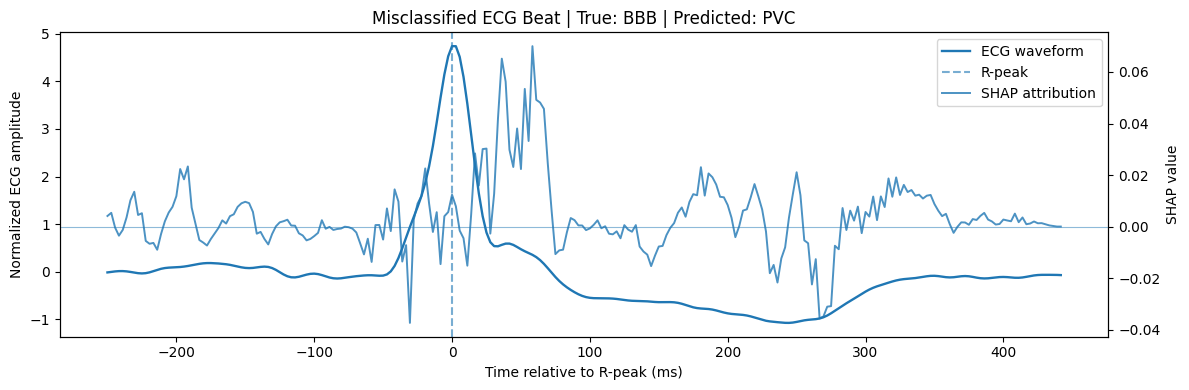

Saved: shap_plots/BBB_to_APB_24688.png


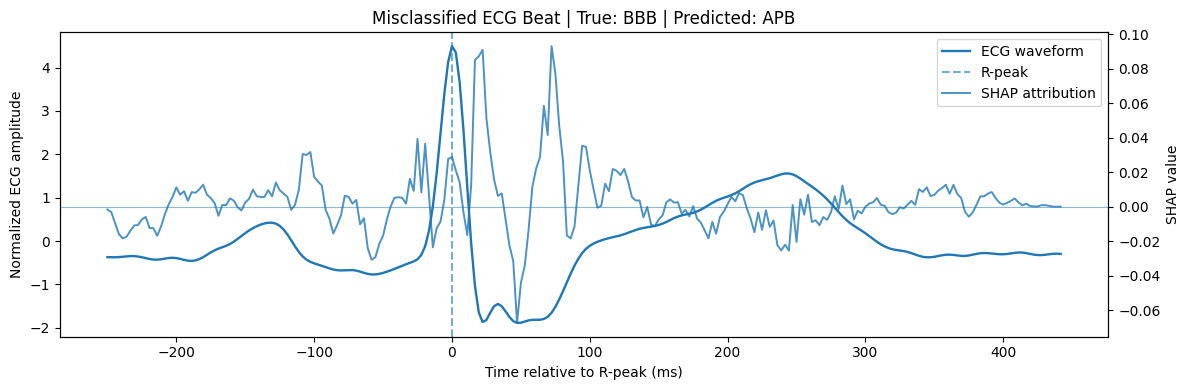

Saved: shap_plots/BBB_to_PVC_29803.png


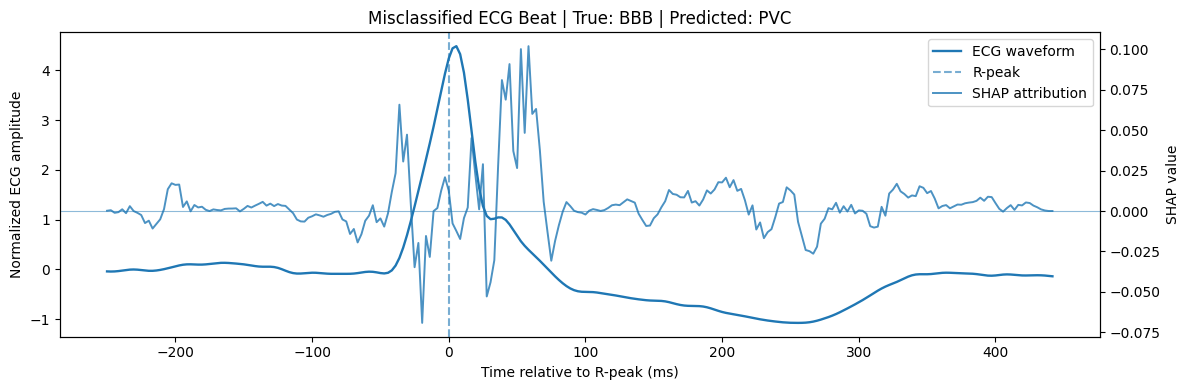

Saved: shap_plots/BBB_to_Normal_7590.png


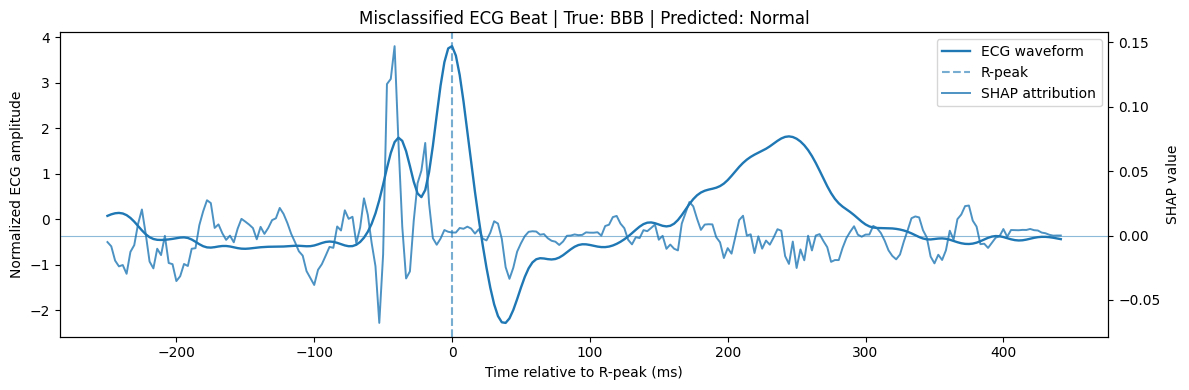

Saved: shap_plots/BBB_to_PVC_24572.png


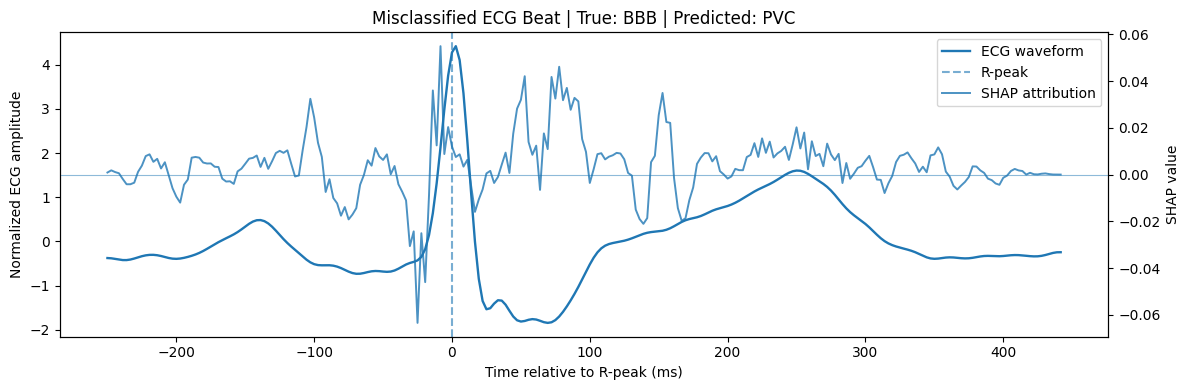

Saved: shap_plots/APB_to_Normal_43386.png


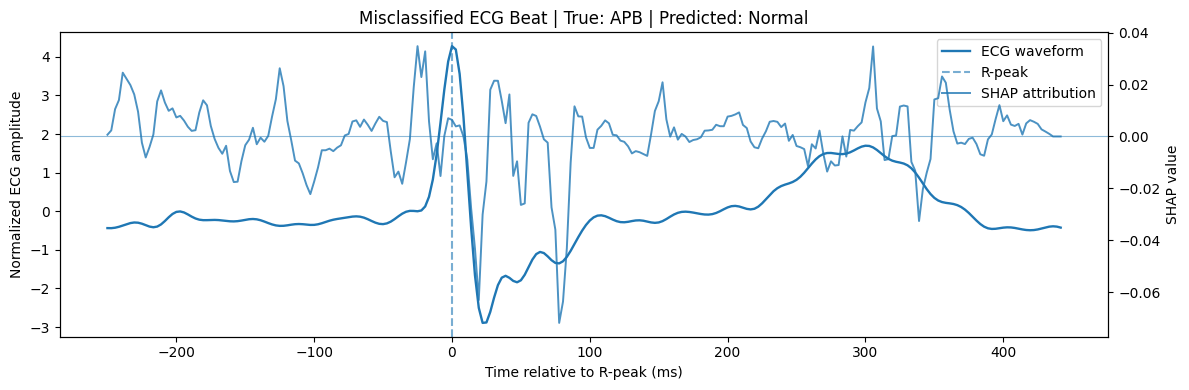

Saved: shap_plots/APB_to_Normal_41651.png


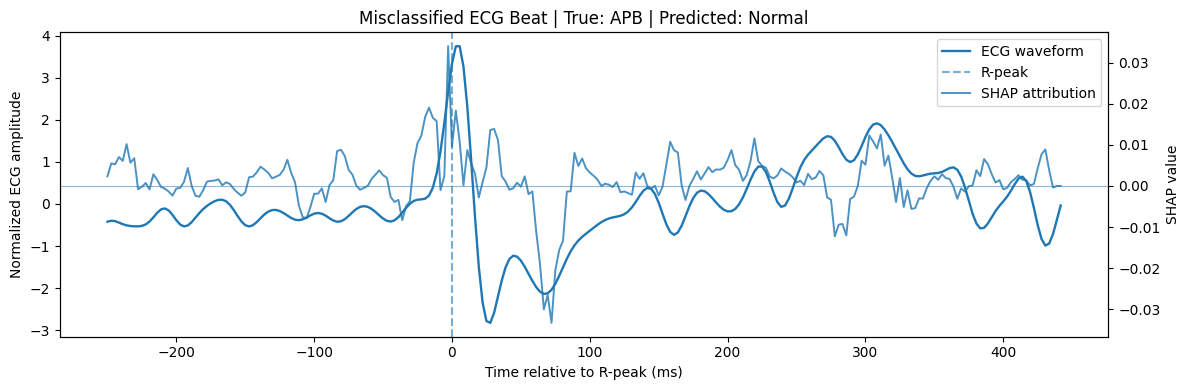

Saved: shap_plots/APB_to_PVC_42507.png


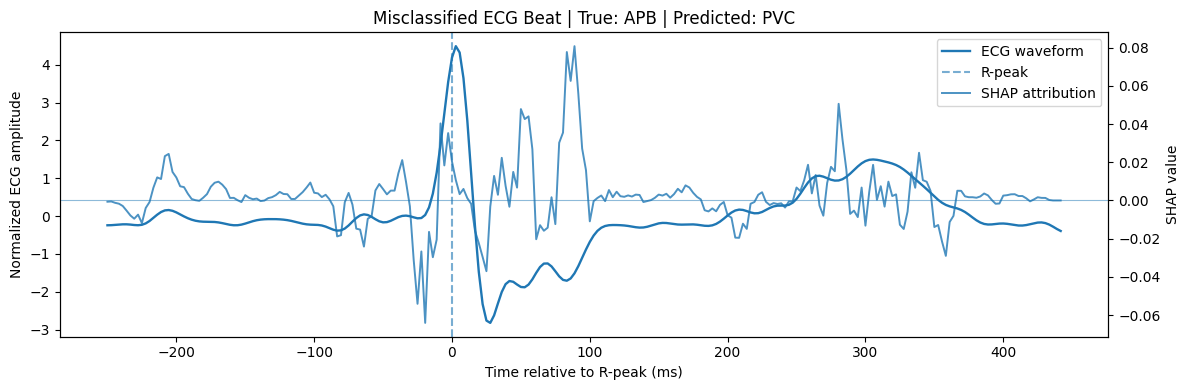

Saved: shap_plots/APB_to_Normal_42971.png


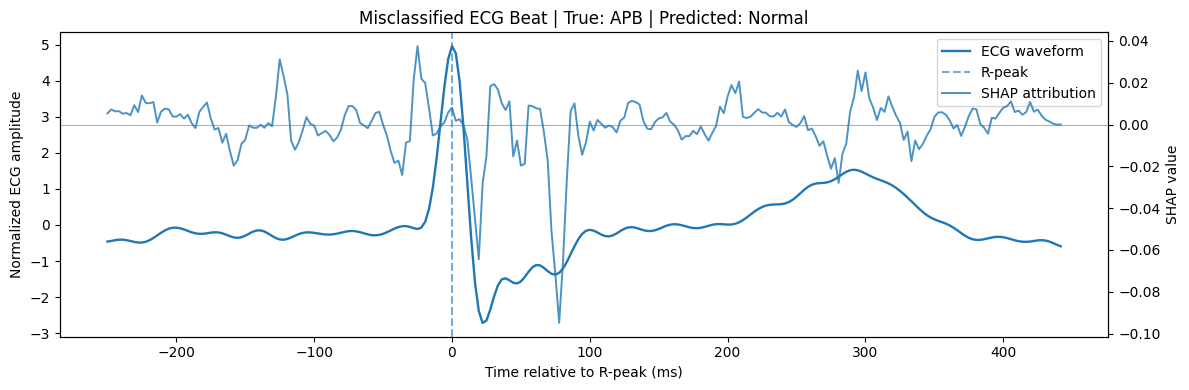

Saved: shap_plots/APB_to_Normal_42917.png


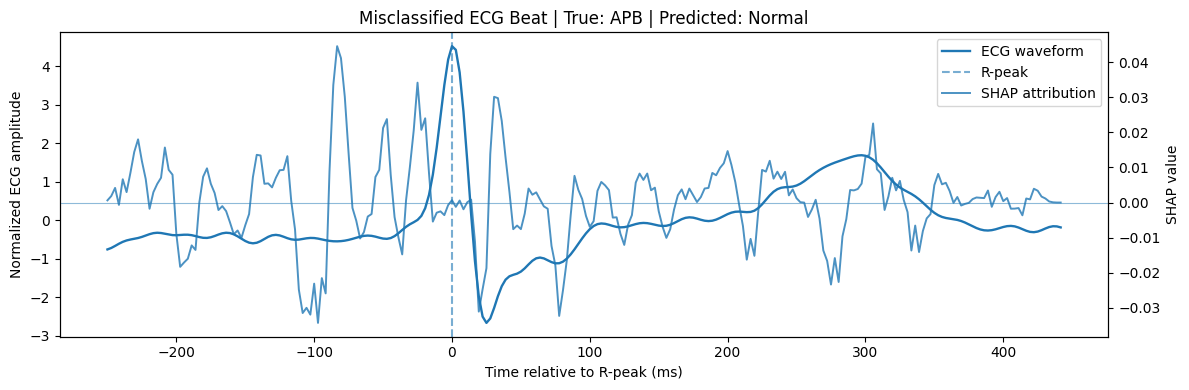

In [17]:
for local_idx, original_idx in enumerate(
    selected_indices
):

    true_class = int(
        y_true2[original_idx]
    )

    predicted_class = int(
        y_pred2[original_idx]
    )

    shap_line = get_class_shap(
        shap_values,
        sample_index=local_idx,
        class_index=predicted_class
    )

    plot_ecg_shap(
        waveform=X_test2[original_idx],
        shap_line=shap_line,
        true_class=true_class,
        predicted_class=predicted_class,
        original_index=original_idx
    )

In [18]:
np.save(
    "y_true2.npy",
    y_true2
)

np.save(
    "y_pred2.npy",
    y_pred2
)

np.save(
    "selected_shap_indices.npy",
    selected_indices
)

print("✅ Predictions and selected indices saved")

✅ Predictions and selected indices saved


In [20]:
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

# Same dataset
X_reshaped = X.reshape(-1, X.shape[1], 1)

num_classes = len(np.unique(y))
y_cat = to_categorical(y, num_classes=num_classes)

# BASELINE: random beat-wise split
X_train1, X_test1, y_train1, y_test1 = train_test_split(
    X_reshaped,
    y_cat,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Baseline train:", X_train1.shape)
print("Baseline test :", X_test1.shape)

Baseline train: (79628, 250, 1)
Baseline test : (19908, 250, 1)


In [21]:
model1 = build_cnn(
    X.shape[1],
    num_classes
)

model1.summary()

/Users/shanjayakasht/project/MLDA PROJECT/Patient-Independent-ECG-Arrhythmia-Classification/.venv/lib/python3.9/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 246, 32)        │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 123, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 119, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 59, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3776)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       241,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 252,484 (986.27 KB)

 Trainable params: 252,484 (986.27 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
y_prob1 = model1.predict(X_test1)

y_pred1 = np.argmax(
    y_prob1,
    axis=1
)

y_true1 = np.argmax(
    y_test1,
    axis=1
)

print("Baseline true:", y_true1.shape)
print("Baseline pred:", y_pred1.shape)


623/623 ━━━━━━━━━━━━━━━━━━━━ 0s 721us/step
Baseline true: (19908,)
Baseline pred: (19908,)


In [23]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

baseline_accuracy = accuracy_score(
    y_true1,
    y_pred1
)

baseline_macro_f1 = f1_score(
    y_true1,
    y_pred1,
    average="macro"
)

print("Baseline Accuracy:", baseline_accuracy)
print("Baseline Macro-F1:", baseline_macro_f1)

print("\nClassification Report:")
print(
    classification_report(
        y_true1,
        y_pred1,
        target_names=[
            "Normal",
            "BBB",
            "APB",
            "PVC"
        ],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_true1,
        y_pred1
    )
)

Baseline Accuracy: 0.1480309423347398
Baseline Macro-F1: 0.07164324490349225

Classification Report:
              precision    recall  f1-score   support

      Normal       0.09      0.00      0.00     14953
         BBB       0.15      0.95      0.26      3066
         APB       0.03      0.01      0.02       509
         PVC       0.02      0.00      0.00      1380

    accuracy                           0.15     19908
   macro avg       0.07      0.24      0.07     19908
weighted avg       0.09      0.15      0.04     19908


Confusion Matrix:
[[   35 14815   100     3]
 [   17  2903     2   144]
 [    5   498     6     0]
 [  340   941    96     3]]


In [24]:
import numpy as np
import tensorflow as tf

from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

# Reproducibility
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

num_classes = len(np.unique(y))

X_reshaped = X.reshape(-1, X.shape[1], 1)
y_cat = to_categorical(y, num_classes=num_classes)

X_train1, X_test1, y_train1, y_test1 = train_test_split(
    X_reshaped,
    y_cat,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("X_train1:", X_train1.shape)
print("X_test1 :", X_test1.shape)
print("y_train1:", y_train1.shape)
print("y_test1 :", y_test1.shape)

print(
    "Train classes:",
    np.unique(np.argmax(y_train1, axis=1), return_counts=True)
)

print(
    "Test classes:",
    np.unique(np.argmax(y_test1, axis=1), return_counts=True)
)

X_train1: (79628, 250, 1)
X_test1 : (19908, 250, 1)
y_train1: (79628, 4)
y_test1 : (19908, 4)
Train classes: (array([0, 1, 2, 3]), array([59808, 12261,  2037,  5522]))
Test classes: (array([0, 1, 2, 3]), array([14953,  3066,   509,  1380]))


In [25]:
model1 = build_cnn(
    X.shape[1],
    num_classes
)

model1.summary()

/Users/shanjayakasht/project/MLDA PROJECT/Patient-Independent-ECG-Arrhythmia-Classification/.venv/lib/python3.9/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 246, 32)        │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 123, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 119, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 59, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3776)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       241,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 252,484 (986.27 KB)

 Trainable params: 252,484 (986.27 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
history1 = model1.fit(
    X_train1,
    y_train1,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    shuffle=True,
    verbose=1
)

Epoch 1/10
1120/1120 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9316 - loss: 0.2289 - val_accuracy: 0.9862 - val_loss: 0.0531
Epoch 2/10
1120/1120 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9813 - loss: 0.0670 - val_accuracy: 0.9883 - val_loss: 0.0478
Epoch 3/10
1120/1120 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9852 - loss: 0.0542 - val_accuracy: 0.9896 - val_loss: 0.0354
Epoch 4/10
1120/1120 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9874 - loss: 0.0456 - val_accuracy: 0.9905 - val_loss: 0.0374
Epoch 5/10
1120/1120 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9894 - loss: 0.0395 - val_accuracy: 0.9911 - val_loss: 0.0339
Epoch 6/10
1120/1120 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9893 - loss: 0.0371 - val_accuracy: 0.9918 - val_loss: 0.0310
Epoch 7/10
1120/1120 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9909 - loss: 0.0319 - val_accuracy: 0.9918 - val_loss: 0.0345
Epoch 8/10
1120/1120 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9914 - loss: 0.0303 - 

In [27]:
train_loss, train_acc = model1.evaluate(
    X_train1,
    y_train1,
    verbose=0
)

test_loss, test_acc = model1.evaluate(
    X_test1,
    y_test1,
    verbose=0
)

print("Train Accuracy:", train_acc)
print("Test Accuracy :", test_acc)

Train Accuracy: 0.9943738579750061
Test Accuracy : 0.9908579587936401


In [28]:
y_prob1 = model1.predict(
    X_test1,
    batch_size=256
)

y_pred1 = np.argmax(
    y_prob1,
    axis=1
)

y_true1 = np.argmax(
    y_test1,
    axis=1
)

print("True :", y_true1.shape)
print("Pred :", y_pred1.shape)

print(
    "Predicted class distribution:",
    np.unique(y_pred1, return_counts=True)
)

78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
True : (19908,)
Pred : (19908,)
Predicted class distribution: (array([0, 1, 2, 3]), array([15034,  3055,   445,  1374]))


In [29]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

baseline_accuracy = accuracy_score(
    y_true1,
    y_pred1
)

baseline_macro_f1 = f1_score(
    y_true1,
    y_pred1,
    average="macro"
)

print(
    "Baseline Accuracy:",
    baseline_accuracy
)

print(
    "Baseline Macro-F1:",
    baseline_macro_f1
)

print("\nClassification Report:")

print(
    classification_report(
        y_true1,
        y_pred1,
        target_names=[
            "Normal",
            "BBB",
            "APB",
            "PVC"
        ],
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_true1,
        y_pred1
    )
)

Baseline Accuracy: 0.990857946554149
Baseline Macro-F1: 0.9652795849959374

Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99     14953
         BBB       1.00      0.99      0.99      3066
         APB       0.96      0.84      0.90       509
         PVC       0.98      0.98      0.98      1380

    accuracy                           0.99     19908
   macro avg       0.98      0.95      0.97     19908
weighted avg       0.99      0.99      0.99     19908


Confusion Matrix:
[[14911     8    13    21]
 [   13  3042     4     7]
 [   81     1   427     0]
 [   29     4     1  1346]]


In [30]:
print("First 20 true:")
print(y_true1[:20])

print("\nFirst 20 predicted:")
print(y_pred1[:20])

print("\nProbability example:")
print(y_prob1[:5])

First 20 true:
[0 0 0 0 0 1 1 0 3 1 3 0 0 0 0 0 0 2 0 1]

First 20 predicted:
[0 0 0 0 0 1 1 0 3 1 3 0 0 0 0 0 0 2 3 1]

Probability example:
[[9.99947429e-01 1.76896640e-11 5.25777177e-05 7.75486875e-09]
 [9.99998689e-01 2.58327566e-13 1.31836634e-06 3.88902854e-10]
 [9.99173939e-01 2.75792382e-15 9.72192197e-07 8.25040508e-04]
 [1.00000000e+00 2.93689292e-12 1.01972493e-08 1.08105683e-13]
 [9.99999881e-01 1.24828208e-13 1.35806900e-07 2.33875284e-13]]


In [31]:
np.save("y_true1.npy", y_true1)
np.save("y_pred1.npy", y_pred1)

model1.save("model1_baseline.keras")

print("✅ Baseline model and predictions saved")

✅ Baseline model and predictions saved


In [32]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support
)

CLASS_NAMES = ["Normal", "BBB", "APB", "PVC"]

def get_metrics(y_true, y_pred):

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3],
        zero_division=0
    )

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Support": support
    }

baseline = get_metrics(y_true1, y_pred1)
corrected = get_metrics(y_true2, y_pred2)

In [33]:
overall_df = pd.DataFrame({
    "Evaluation": [
        "Baseline (Random Beat-wise)",
        "Corrected (Patient-wise DS1/DS2)"
    ],
    "Accuracy": [
        baseline["Accuracy"],
        corrected["Accuracy"]
    ],
    "Macro-F1": [
        baseline["Macro-F1"],
        corrected["Macro-F1"]
    ]
})

overall_df = overall_df.round(3)

overall_df

,Evaluation,Accuracy,Macro-F1
0,Baseline (Random Beat-wise),0.991,0.965
1,Corrected (Patient-wise DS1/DS2),0.694,0.369


In [34]:
rows = []

for i, class_name in enumerate(CLASS_NAMES):

    rows.append({
        "Class": class_name,

        "Baseline Precision":
            baseline["Precision"][i],

        "Baseline Recall":
            baseline["Recall"][i],

        "Baseline F1":
            baseline["F1"][i],

        "Corrected Precision":
            corrected["Precision"][i],

        "Corrected Recall":
            corrected["Recall"][i],

        "Corrected F1":
            corrected["F1"][i]
    })

class_comparison_df = pd.DataFrame(rows).round(3)

class_comparison_df

,Class,Baseline Precision,Baseline Recall,Baseline F1,Corrected Precision,Corrected Recall,Corrected F1
0,Normal,0.992,0.997,0.994,0.873,0.841,0.857
1,BBB,0.996,0.992,0.994,0.177,0.013,0.025
2,APB,0.960,0.839,0.895,0.046,0.138,0.069
3,PVC,0.980,0.975,0.977,0.367,0.928,0.526


In [35]:
overall_df.to_csv(
    "overall_baseline_vs_corrected.csv",
    index=False
)

class_comparison_df.to_csv(
    "classwise_baseline_vs_corrected.csv",
    index=False
)

print("✅ Comparison tables saved")

✅ Comparison tables saved


In [36]:
CLASS_MAP = {
    0: "Normal",
    1: "BBB",
    2: "APB",
    3: "PVC"
}

patient_rows = []

for class_id, class_name in CLASS_MAP.items():

    for split_name, records in [
        ("DS1 Train", DS1),
        ("DS2 Test", DS2)
    ]:

        mask = (
            (y == class_id)
            &
            np.isin(patient_ids, records)
        )

        record_ids = np.unique(
            patient_ids[mask]
        )

        patient_rows.append({
            "Class": class_name,
            "Split": split_name,
            "Beat Count": int(np.sum(mask)),
            "Distinct Records": len(record_ids),
            "Record IDs": ", ".join(
                map(str, record_ids)
            )
        })

patient_distribution_df = pd.DataFrame(
    patient_rows
)

patient_distribution_df

,Class,Split,Beat Count,Distinct Records,Record IDs
0,Normal,DS1 Train,38120,19,"101, 106, 108, 112, 114, 115, 116, 119, 122, 1..."
1,Normal,DS2 Test,36641,20,"100, 103, 105, 113, 117, 121, 123, 200, 202, 2..."
2,BBB,DS1 Train,7728,4,"109, 118, 124, 207"
3,BBB,DS2 Test,7599,5,"111, 212, 214, 231, 232"
4,APB,DS1 Train,810,14,"101, 108, 112, 114, 116, 118, 124, 201, 205, 2..."
5,APB,DS2 Test,1736,13,"100, 103, 117, 121, 200, 202, 213, 219, 222, 2..."
6,PVC,DS1 Train,3683,17,"106, 108, 109, 114, 116, 118, 119, 124, 201, 2..."
7,PVC,DS2 Test,3219,16,"100, 105, 111, 121, 123, 200, 202, 210, 213, 2..."


In [37]:
patient_distribution_df.to_csv(
    "patient_class_distribution.csv",
    index=False
)

print("✅ Patient distribution table saved")

✅ Patient distribution table saved


# ECG Patient-Independent Arrhythmia Classification
## Combined Corrected Evaluation, Baseline Comparison and SHAP Analysis

## 1. Dataset Loading and Verification

## 2. Patient-wise DS1 / DS2 Split
### Person 2 — Corrected Evaluation

## 3. Shared CNN Architecture

## 4. Corrected Patient-wise Model Training

## 5. Corrected Model Evaluation

## 6. SHAP Explainability
### BBB and APB Misclassification Analysis

## 7. Person 3 — Random Beat-wise Baseline Evaluation

This section evaluates the same frozen CNN architecture using a random 80/20 beat-wise split without considering patient identity.

In [49]:
import numpy as np
import tensorflow as tf

from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

# Reproducibility
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

num_classes = len(np.unique(y))

# Conv1D input shape
X_baseline = X.reshape(-1, X.shape[1], 1)

# One-hot encode labels
y_baseline = to_categorical(
    y,
    num_classes=num_classes
)

# Random beat-wise 80/20 split
# IMPORTANT: patient_ids are NOT used here
X_train1, X_test1, y_train1, y_test1 = train_test_split(
    X_baseline,
    y_baseline,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("X_train1:", X_train1.shape)
print("X_test1 :", X_test1.shape)
print("y_train1:", y_train1.shape)
print("y_test1 :", y_test1.shape)

X_train1: (79628, 250, 1)
X_test1 : (19908, 250, 1)
y_train1: (79628, 4)
y_test1 : (19908, 4)


In [50]:
model1 = build_cnn(
    X.shape[1],
    num_classes
)

model1.summary()

/Users/shanjayakasht/project/MLDA PROJECT/Patient-Independent-ECG-Arrhythmia-Classification/.venv/lib/python3.9/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 246, 32)        │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 123, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 119, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 59, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3776)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       241,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 252,484 (986.27 KB)

 Trainable params: 252,484 (986.27 KB)

 Non-trainable params: 0 (0.00 B)

In [51]:
model1 = build_cnn(
    X.shape[1],
    num_classes
)

history1 = model1.fit(
    X_train1,
    y_train1,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    shuffle=True,
    verbose=1
)

Epoch 1/10
1120/1120 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9290 - loss: 0.2370 - val_accuracy: 0.9857 - val_loss: 0.0495
Epoch 2/10
1120/1120 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9807 - loss: 0.0733 - val_accuracy: 0.9893 - val_loss: 0.0410
Epoch 3/10
1120/1120 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9845 - loss: 0.0582 - val_accuracy: 0.9886 - val_loss: 0.0387
Epoch 4/10
1120/1120 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9857 - loss: 0.0504 - val_accuracy: 0.9906 - val_loss: 0.0363
Epoch 5/10
1120/1120 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9875 - loss: 0.0432 - val_accuracy: 0.9915 - val_loss: 0.0320
Epoch 6/10
1120/1120 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9881 - loss: 0.0407 - val_accuracy: 0.9905 - val_loss: 0.0367
Epoch 7/10
1120/1120 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9894 - loss: 0.0366 - val_accuracy: 0.9916 - val_loss: 0.0352
Epoch 8/10
1120/1120 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9894 - loss: 0.0336 - 

In [52]:
y_prob1 = model1.predict(
    X_test1,
    batch_size=256
)

y_pred1 = np.argmax(
    y_prob1,
    axis=1
)

y_true1 = np.argmax(
    y_test1,
    axis=1
)

print("y_true1:", y_true1.shape)
print("y_pred1:", y_pred1.shape)

78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
y_true1: (19908,)
y_pred1: (19908,)


In [53]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

baseline_accuracy = accuracy_score(
    y_true1,
    y_pred1
)

baseline_macro_f1 = f1_score(
    y_true1,
    y_pred1,
    average="macro"
)

print("Baseline Accuracy:", baseline_accuracy)
print("Baseline Macro-F1:", baseline_macro_f1)

print("\nClassification Report:")

print(
    classification_report(
        y_true1,
        y_pred1,
        target_names=[
            "Normal",
            "BBB",
            "APB",
            "PVC"
        ],
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_true1,
        y_pred1
    )
)

Baseline Accuracy: 0.9907072533654813
Baseline Macro-F1: 0.9636920526220523

Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99     14953
         BBB       0.99      0.99      0.99      3066
         APB       0.97      0.82      0.89       509
         PVC       0.99      0.97      0.98      1380

    accuracy                           0.99     19908
   macro avg       0.98      0.95      0.96     19908
weighted avg       0.99      0.99      0.99     19908


Confusion Matrix:
[[14922     6     9    16]
 [   12  3048     4     2]
 [   89     1   419     0]
 [   34    11     1  1334]]


In [54]:
model1.save("model1_baseline.keras")

np.save("y_true1.npy", y_true1)
np.save("y_pred1.npy", y_pred1)

print("✅ Person 3 baseline work saved")

✅ Person 3 baseline work saved


## 8. Baseline vs Corrected Comparison

- Baseline Accuracy: **99.07%**
- Corrected Accuracy: **69.43%**

- Baseline Macro-F1: **96.37%**
- Corrected Macro-F1: **36.94%**

In [55]:
baseline = get_metrics(y_true1, y_pred1)
corrected = get_metrics(y_true2, y_pred2)

overall_df = pd.DataFrame({
    "Evaluation": [
        "Baseline (Random Beat-wise)",
        "Corrected (Patient-wise DS1/DS2)"
    ],
    "Accuracy": [
        baseline["Accuracy"],
        corrected["Accuracy"]
    ],
    "Macro-F1": [
        baseline["Macro-F1"],
        corrected["Macro-F1"]
    ]
}).round(4)

overall_df.to_csv(
    "overall_baseline_vs_corrected.csv",
    index=False
)

overall_df

,Evaluation,Accuracy,Macro-F1
0,Baseline (Random Beat-wise),0.9907,0.9637
1,Corrected (Patient-wise DS1/DS2),0.6943,0.3694


In [56]:
rows = []

for i, class_name in enumerate(["Normal", "BBB", "APB", "PVC"]):
    rows.append({
        "Class": class_name,
        "Baseline Precision": baseline["Precision"][i],
        "Baseline Recall": baseline["Recall"][i],
        "Baseline F1": baseline["F1"][i],
        "Corrected Precision": corrected["Precision"][i],
        "Corrected Recall": corrected["Recall"][i],
        "Corrected F1": corrected["F1"][i]
    })

class_comparison_df = pd.DataFrame(rows).round(4)

class_comparison_df.to_csv(
    "classwise_baseline_vs_corrected.csv",
    index=False
)

class_comparison_df

,Class,Baseline Precision,Baseline Recall,Baseline F1,Corrected Precision,Corrected Recall,Corrected F1
0,Normal,0.9910,0.9979,0.9945,0.8734,0.8414,0.8571
1,BBB,0.9941,0.9941,0.9941,0.1774,0.0134,0.0250
2,APB,0.9677,0.8232,0.8896,0.0462,0.1382,0.0693
3,PVC,0.9867,0.9667,0.9766,0.3674,0.9279,0.5264


## 9. Class-wise Record Diversity Analysis
### Record-level Distribution

| Class | DS1 Train Beats | Train Records | DS2 Test Beats | Test Records |
|---|---:|---:|---:|---:|
| Normal | 38,120 | 19 | 36,641 | 20 |
| BBB | 7,728 | 4 | 7,599 | 5 |
| APB | 810 | 14 | 1,736 | 13 |
| PVC | 3,683 | 17 | 3,219 | 16 |

### Interpretation

The class distribution shows that raw beat count alone does not represent the diversity available to the CNN.

BBB contains thousands of beats, but the DS1 training set contains BBB beats from only four distinct MIT-BIH records. This provides limited record-level diversity and helps explain why BBB recall falls sharply from 0.99 in the beat-wise baseline to 0.01 in the patient-wise evaluation.

APB appears across more records, but only 810 APB training beats are available. This limited number of examples, combined with inter-record morphological variation, likely contributes to the reduction in APB recall from 0.84 to 0.14.

PVC is represented across 17 training records and 16 testing records. Its broader record-level coverage appears to support stronger generalization, allowing recall to remain high at 0.93 under the patient-independent evaluation.

## 10. Final Findings and Conclusion
## Final Findings

The experiment demonstrates a substantial difference between beat-wise and patient-wise ECG evaluation.

| Evaluation | Accuracy | Macro-F1 |
|---|---:|---:|
| Random Beat-wise Baseline | 99.09% | 96.53% |
| Patient-wise DS1/DS2 | 69.43% | 36.94% |

The random beat-wise split produces extremely high performance because beats from the same MIT-BIH record can occur in both the training and testing sets. This allows the CNN to benefit from highly similar record-specific ECG morphology.

When record overlap is completely removed using the DS1/DS2 split, performance decreases substantially.

The largest class-specific changes were:

- Normal recall: **1.00 → 0.84**
- BBB recall: **0.99 → 0.01**
- APB recall: **0.84 → 0.14**
- PVC recall: **0.98 → 0.93**

BBB showed the strongest degradation, consistent with its limited record-level diversity in the training data. APB also generalized poorly because relatively few training beats were available. PVC remained comparatively robust across unseen records.

SHAP analysis of misclassified BBB and APB beats further provides insight into which ECG waveform regions influenced incorrect predictions.

## Conclusion

This study shows that random beat-wise evaluation can substantially overestimate the real-world generalization ability of ECG arrhythmia classifiers.

A CNN achieving approximately 99% accuracy under a random beat-wise split achieved only approximately 69% accuracy when evaluated on unseen MIT-BIH records.

Therefore, patient-independent or record-independent evaluation should be considered essential when reporting ECG arrhythmia classification performance.

Future work can extend this study using deeper architectures, additional ECG databases, cross-dataset validation, and improved techniques for handling minority arrhythmia classes.